# 🔧 Setup

In [1]:
from pipeline import get_preprocessing_pipeline, get_feature_names, get_target_name, build_model_pipeline

from sklearn.model_selection import (train_test_split, GridSearchCV)
from sklearn.base import BaseEstimator
from sklearn.metrics import (accuracy_score, recall_score, precision_score, average_precision_score, precision_recall_curve, auc)

from sklearn.linear_model import (LogisticRegression)


import data_loader
import evaluation 
from data_visualizer import create_fig

PATH_DATA ='data/raw/Telco_customer_churn.xlsx'
SEED = 4586

# 📦 Train-Test split

In [2]:
df = data_loader.load_churn_data(PATH_DATA)

In [3]:
X = df[get_feature_names(False)]
y = df[get_target_name(False)]

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=SEED, stratify=y)
y_test.value_counts()

Churn Value
0    1294
1     467
Name: count, dtype: int64

# 🎯 Métricas alvo
>- **`recall`** >= `0.80` : `recall` é a porcentagem de casos positivos (nesse caso `churn_value = 1`) que o modelo capturou. Um recall 0.80 significa que, de todos os clientes que realmente cancelaram, o modelo identificou corretamente 80%. Um `recall` baixo significa que o modelo não está detectando muitos dos casos positivos.
>- **`precision`** >= `0.65` :  `precision` é a porcentagem de predições positivas que o modelo acertou. Um precision de 0.65 significa que, dos clientes que o modelo apontou como estando em risco, 65% realmente cancelaram (e portanto tem `churn_value = 1`). Um `precision` baixo significa que o modelo está retornando muitos falsos positivos.

Vamos fazer ajustes para chegar o mais perto possível dessas métricas com todos os nossos modelos, inclusive o baseline.
>- **`GridSearchCV`** Testará diferentes parâmetros do modelo para encontrar o que performa melhor, e testará esses parâmetros em fatias diferentes do dataset para checar consistência
>- **`evaluation.get_oof_proba`** Retornará a probabilidade de `churn_value = 1` calculada pelo modelo, assim nos deixando determinar uma probabilidade mínima (`threshold`) em vez de utilizar o default de nossos modelos
>- **`evaluation.plot_roc_pr`** Desenhará gráficos ROC e PR:
>- **`Um gráfico ROC (Receiver Operating Characteristic) curve`** plota `True Positive Rate x False Positive Rate` ao longo de `threshold`. A área em baixo dessa curva (`AUC - Area Under The Curve`) nos diz a qualidade desse modelo, `0.5` é um modelo que não performa melhor que simplesmente escolher aleatoriamente, e `1.0` é um modelo perfeito.
>- **`Um gráfico PR (Precision-Recall) curve`** plota `Precision x Recall` ao longo de `threshold`. A `AUC` nos diz a qualidade desse modelo. Sua baseline é a `porcentagem de casos positivos no nosso database` (no nosso caso, ~`0.26`) e `1.0` é um modelo perfeito.

# 📝 Baseline
Faremos um modelo simples de LogisticRegression para servir como um baseline aos nossos modelos mais complexos.

In [5]:
model_lr = LogisticRegression()
pipeline_lr = build_model_pipeline(
        model_lr,
        scale=True
    )

models = {
    'lr':pipeline_lr
}

models_grid_params = {
    'lr':{
        'param_grid':{
            'model__solver': ['saga'],
            'model__l1_ratio': [0, 0.25, 0.5, 0.75, 1],  # 0 = pure L2, 1 = pure L1
            'model__C': [0.1, 1.0, 10.0],
            'model__max_iter': [1000],  # Increased so saga converges cleanly
            'model__class_weight':['balanced']
            },
        'scoring':'average_precision'
        }
    }

In [6]:
grid_results = evaluation.grid_search_models(models, models_grid_params, X_train, y_train, X_test)

In [7]:
evaluation.display_grid_results(grid_results)

RESULTS FOR "lr"
Best Parameters: {'model__C': 0.1, 'model__class_weight': 'balanced', 'model__l1_ratio': 0.5, 'model__max_iter': 1000, 'model__solver': 'saga'}
Best Cross-Val AUC-PR: 0.6708


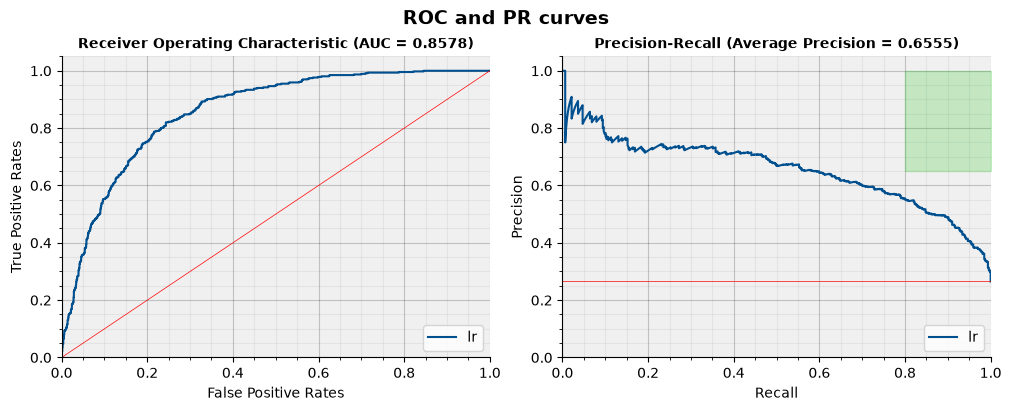

In [22]:
import importlib
import data_visualizer

# After making changes to my_module.py, run this:
importlib.reload(data_visualizer)
importlib.reload(evaluation)


y_test, y_proba = evaluation._validate_binary(y_test, grid_results['lr']['y_proba'])

evaluation.plot_roc_pr(
    y_test,
    grid_results['lr']['y_proba'],
    label='lr',
    target_recall=0.8,
    min_precision=0.65
)